# 海关产品结构与 ITC 国家排名验证

## tl;dr

原算法下调整金额指标没有改变 11 国排序。占比作为第六项指标、权重 20% 时，前五成员不变；直接乘原得分的强化诊断让泰国替换日本。完整解读见 `output/验证结果与建议.md`。原数据、原 ITC 结果与 main.tex 均未改动。

## Context & Methods

海关为 2026 年 1—8 月中国出口金额占比，ITC 主要为 2025 年需求和 2020—2025 年增长。不是台数占比。原模型五权重 0.30/0.10/0.10/0.30/0.20。

### Key Assumptions

中国出口结构不能直接代表目的地全部进口结构；迁移仅是压力测试。排名样本 11 国，越南/老挝/缅甸不补值，美国只保留参照。置换 p 值是标签交换参照，不是因果证据。

执行说明：此笔记由顺序 Python 代码单元执行器运行并保存输出；当前环境没有 Jupyter 内核、nbclient、nbformat。

In [1]:
from pathlib import Path
import sys, json
ROOT = Path.cwd()
assert (ROOT / 'config.json').is_file(), '请在 ITC-model-verification 目录运行'
sys.dont_write_bytecode = True
sys.path.insert(0, str(ROOT / 'code'))
import verify_model as v
import numpy as np
print(json.dumps(json.loads((ROOT/'config.json').read_text(encoding='utf-8')), ensure_ascii=False, indent=2))

{
  "analysis_id": "20261010-HS85081110-share-ITC-ranking-verification",
  "customs_period": "2026-01/2026-08",
  "customs_period_basis": "User-supplied period and pre-existing share table; raw exports have no date column",
  "ratio_basis": "CNY export value; not quantity",
  "permutation_draws": 199999,
  "bootstrap_draws": 20000,
  "random_seed": 20261010,
  "alpha": 0.05,
  "share_indicator_weights": [
    0.05,
    0.1,
    0.2,
    0.4
  ],
  "composition_exponents": [
    0.25,
    0.5,
    1.0
  ],
  "stress_grid_step": 0.005,
  "practical_thresholds": {
    "top5_membership_changed": true,
    "max_absolute_rank_change_at_least": 3,
    "spearman_below": 0.9,
    "kendall_below": 0.8,
    "note": "Analyst-defined screening flags fixed before calculation, not statistical significance standards. Any flag merits attention, not proof of a true narrow-HS ranking."
  }
}


## Data

### 1. 检查冻结输入与国家连接

原始来源和查询见 `metadata/source_ledger.csv` 与 `metadata/official_itc_source_ledger.csv`；按源文件字节 SHA-256 核验。

In [2]:
cfg,countries,sample,x,s,w,orig,ranks,lineage,checks = v.load_data()
manifest = v.readcsv(ROOT/'metadata/input_file_manifest.csv')
assert all(v.sha(ROOT/r['snapshot_path']) == r['sha256'] for r in manifest)
print('国家  占比  原得分  原名次')
for c in sample:
    print(f"{c['market']}: {c['narrow_share']:.2%}, {c['original_score']:.6f}, {c['original_rank']}")
print('已匹配国家:',len(sample),'；海关覆盖:',len(countries),'；源快照:',len(manifest))

国家  占比  原得分  原名次
韩国: 53.22%, 0.896282, 1
澳大利亚: 61.88%, 0.846239, 2
马来西亚: 34.34%, 0.793578, 3
新西兰: 37.53%, 0.780820, 4
日本: 24.85%, 0.770295, 5
印度尼西亚: 22.50%, 0.750149, 6
泰国: 34.78%, 0.698047, 7
菲律宾: 17.68%, 0.641689, 8
柬埔寨: 21.88%, 0.562982, 9
新加坡: 47.36%, 0.416286, 10
文莱: 1.75%, 0.000000, 11
已匹配国家: 11 ；海关覆盖: 15 ；源快照: 34


### 2. 独立复现原模型

同时核对向量实现和不依赖该计算函数的标量实现。

In [3]:
baseline = v.topsis(x,w)
assert np.array_equal(baseline[1], ranks)
assert np.max(np.abs(baseline[0]-orig)) < 1e-12
assert np.max(np.abs(v.independent_baseline(x,w)-orig)) < 1e-12
print('原模型最大得分误差:',float(np.max(np.abs(baseline[0]-orig))))
print('独立方法单元测试:',len(v.unit_tests()),'项通过')

原模型最大得分误差: 0.0
独立方法单元测试: 10 项通过


## Results

### 3. 相关检验、置换与重抽样

Pearson/Spearman/Kendall 分别检验线性、单调及国家对次序关联。多重检验校正后，不能把单项 p<0.05 写成确定结论。

In [4]:
correlations, leave_one, _ = v.stats_tests(s,orig,cfg['random_seed'],cfg['permutation_draws'],cfg['bootstrap_draws'])
for row in correlations:
    print(f"{row['method']}: coef={row['coefficient']:.6f}, permutation p={row['p_value_permutation_two_sided']:.6f}, Holm p={row['p_value_holm_3_tests']:.6f}, country-resampling interval=[{row['bootstrap_percentile_95_low']:.4f},{row['bootstrap_percentile_95_high']:.4f}]")
print('剔除文莱的 Pearson:',next(r['coefficient'] for r in leave_one if r['method']=='pearson' and sample[r['excluded_index']]['iso3']=='BRN'))

pearson: coef=0.626171, permutation p=0.039095, Holm p=0.080250, country-resampling interval=[-0.2318,0.9066]
spearman: coef=0.654545, permutation p=0.034295, Holm p=0.080250, country-resampling interval=[-0.0481,0.9720]
kendall_tau_b: coef=0.527273, permutation p=0.026750, Holm p=0.080250, country-resampling interval=[-0.0196,0.9184]
剔除文莱的 Pearson: 0.29284473443390463


### 4. 占比与原得分图

图源：海关逐国人民币金额及冻结原模型得分，不做跨年度金额合并。

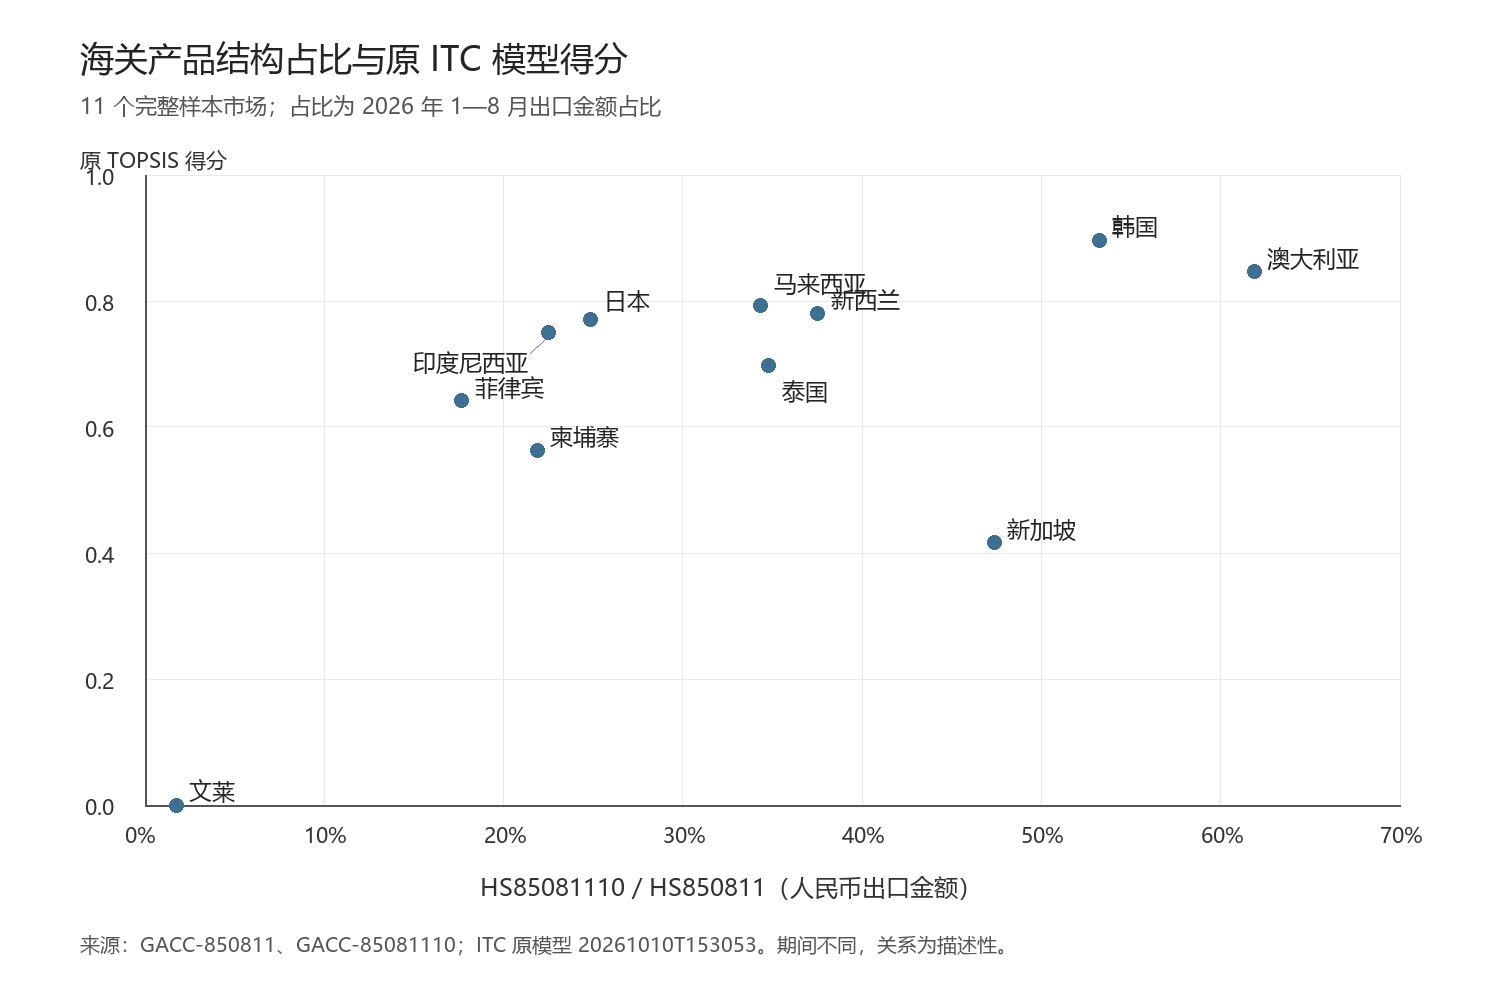

In [5]:
def show_image(path):
    if '__record_image' in globals():
        __record_image(path)
    else:
        try:
            from IPython.display import display, Image
            display(Image(filename=str(path)))
        except ImportError:
            print('图像文件:',path)
plot_details = v.make_scenarios(cfg,sample,x,s,w,orig,ranks)[1]
v.draw_figures(sample,s,orig,plot_details)
show_image(ROOT/'output/figures/share_vs_score.png')

### 5. 占比情景下的名次变化

同时看总体秩相关及前五成员替换。原名次越小越好；括号中的正数表示名次改善。

baseline: Spearman=1.0000, Kendall=1.0000, max shift=0, Top5 overlap=5/5, KOR;AUS;MYS;NZL;JPN
add_share_w0.05: Spearman=1.0000, Kendall=1.0000, max shift=0, Top5 overlap=5/5, KOR;AUS;MYS;NZL;JPN
add_share_w0.10: Spearman=1.0000, Kendall=1.0000, max shift=0, Top5 overlap=5/5, KOR;AUS;MYS;NZL;JPN
add_share_w0.20: Spearman=0.9818, Kendall=0.9273, max shift=1, Top5 overlap=5/5, KOR;AUS;NZL;MYS;JPN
add_share_w0.40: Spearman=0.8364, Kendall=0.6727, max shift=4, Top5 overlap=4/5, AUS;KOR;NZL;MYS;THA
scale_untapped_only_a0.25: Spearman=1.0000, Kendall=1.0000, max shift=0, Top5 overlap=5/5, KOR;AUS;MYS;NZL;JPN
scale_size_and_untapped_a0.25: Spearman=1.0000, Kendall=1.0000, max shift=0, Top5 overlap=5/5, KOR;AUS;MYS;NZL;JPN
scale_untapped_only_a0.50: Spearman=1.0000, Kendall=1.0000, max shift=0, Top5 overlap=5/5, KOR;AUS;MYS;NZL;JPN
scale_size_and_untapped_a0.50: Spearman=1.0000, Kendall=1.0000, max shift=0, Top5 overlap=5/5, KOR;AUS;MYS;NZL;JPN
scale_untapped_only_a1.00: Spearman=1.0000, Kendal

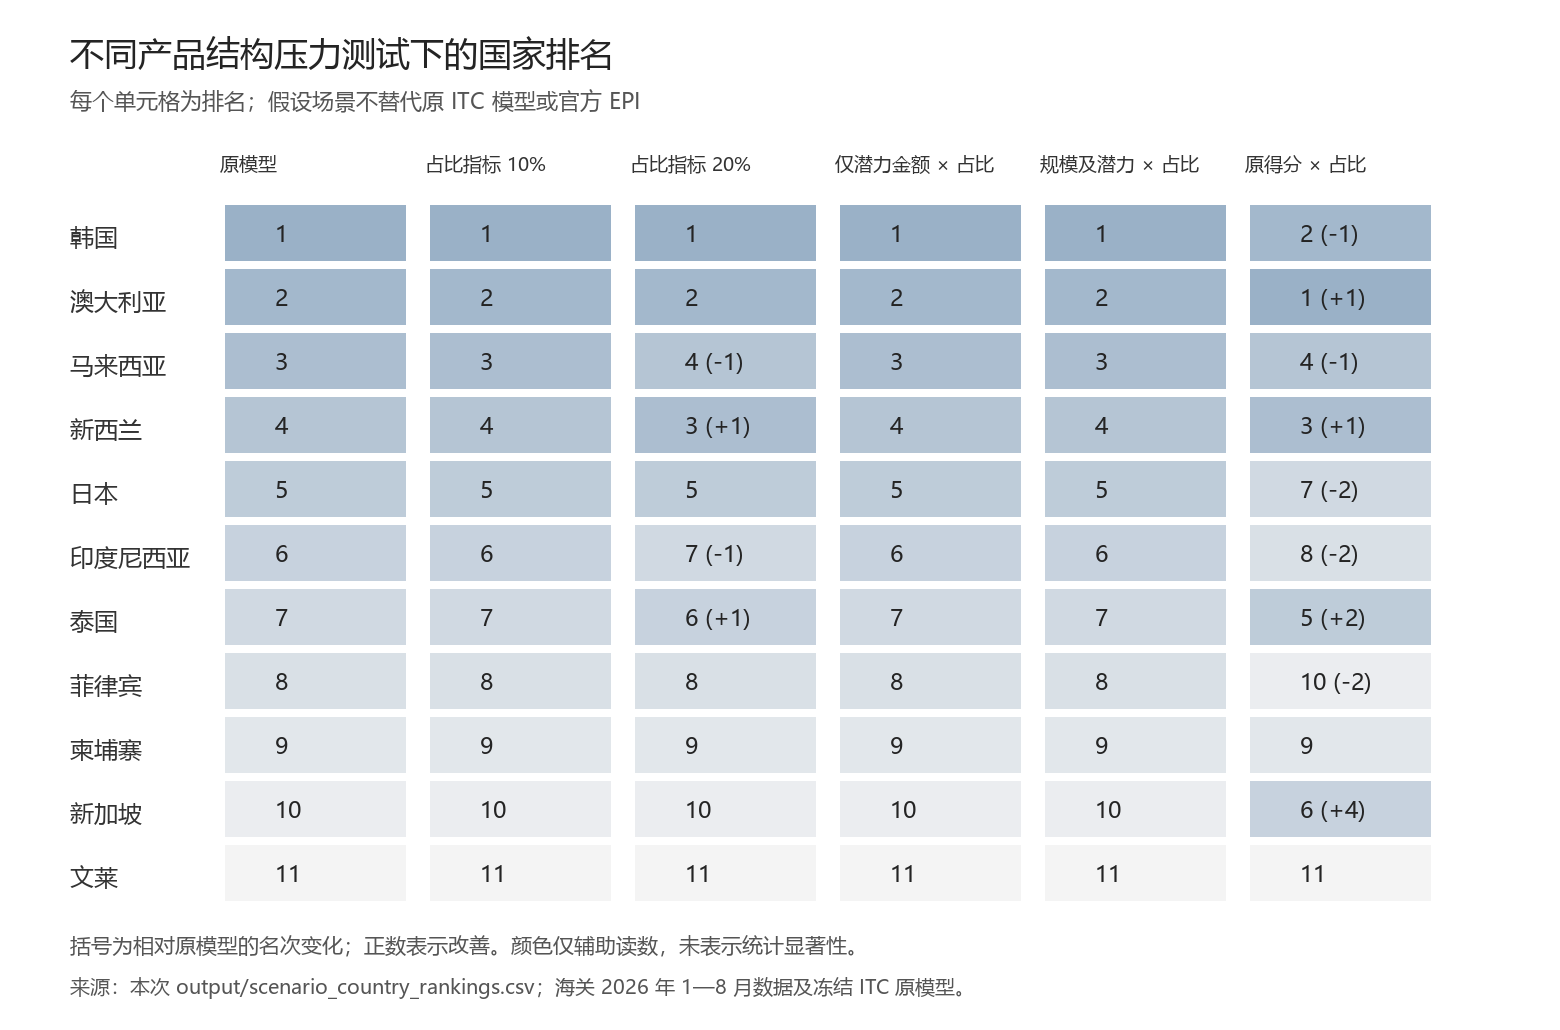

In [6]:
scenarios, detail, matrices, weights = v.make_scenarios(cfg,sample,x,s,w,orig,ranks)
for row in scenarios:
    print(f"{row['scenario']}: Spearman={row['spearman_ranks']:.4f}, Kendall={row['kendall_tau_b_ranks']:.4f}, max shift={row['max_absolute_rank_change']}, Top5 overlap={row['top5_overlap_count']}/5, {row['top5_order']}")
show_image(ROOT/'output/figures/scenario_rank_comparison.png')

### 6. 同期宽/窄出口金额排名的直接比较

这个比较无需把占比迁移到进口需求，但它只检验中国现有出口规模排序，不是市场吸引力排序。

In [7]:
observed = v.readcsv(ROOT/'output/observed_export_rank_comparison.csv')
all14 = [r for r in observed if r['scope']=='all_RCEP14']
a = np.array([int(r['broad_export_rank']) for r in all14])
b = np.array([int(r['narrow_export_rank']) for r in all14])
print('14 国同期出口金额排名关联:',v.association(a,b))
for row in sorted(all14,key=lambda r:int(r['narrow_export_rank']))[:5]:
    print(row['market'],row['broad_export_rank'],'→',row['narrow_export_rank'])

14 国同期出口金额排名关联: {'pearson': 0.978021978021978, 'spearman': 0.978021978021978, 'kendall_tau_b': 0.9120879120879121}
澳大利亚 3 → 1
韩国 2 → 2
日本 1 → 3
越南 4 → 4
泰国 5 → 5


## Takeaways

现有五国可保留为研究范围，不能将其写成已确认的窄编码官方排名。日本是强结构偏好下的边界敏感市场，泰国可作备选。越南占比较高但缺原模型主指标，不能把缺名次当作低吸引力。完整公式、敏感网格、来源与访问日期缺口见 `methodology.md` 和 `metadata/`。